# Cell 01: Install Project Libraries

In [24]:


%pip install -q tensorflow-datasets
%pip install -q qiskit qiskit-aer
%pip install -q scikit-learn
%pip install -q importlib_resources

# Cell 02: Import Project Libraries

In [25]:


import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Check versions
print("TensorFlow:", tf.__version__)
print("Qiskit imported successfully")
print("All libraries loaded successfully")

TensorFlow: 2.21.0
Qiskit imported successfully
All libraries loaded successfully


# Cell 03: Load Malaria Dataset

In [26]:

dataset, info = tfds.load(
    "malaria",
    split="train",
    as_supervised=True,
    with_info=True,
    data_dir="/content/quantum_malaria_data"
)

class_names = info.features["label"].names

print("Total Images:", info.splits["train"].num_examples)
print("Classes:", class_names)

Total Images: 27558
Classes: ['parasitized', 'uninfected']


# Cell 04: Visualize Malaria Dataset

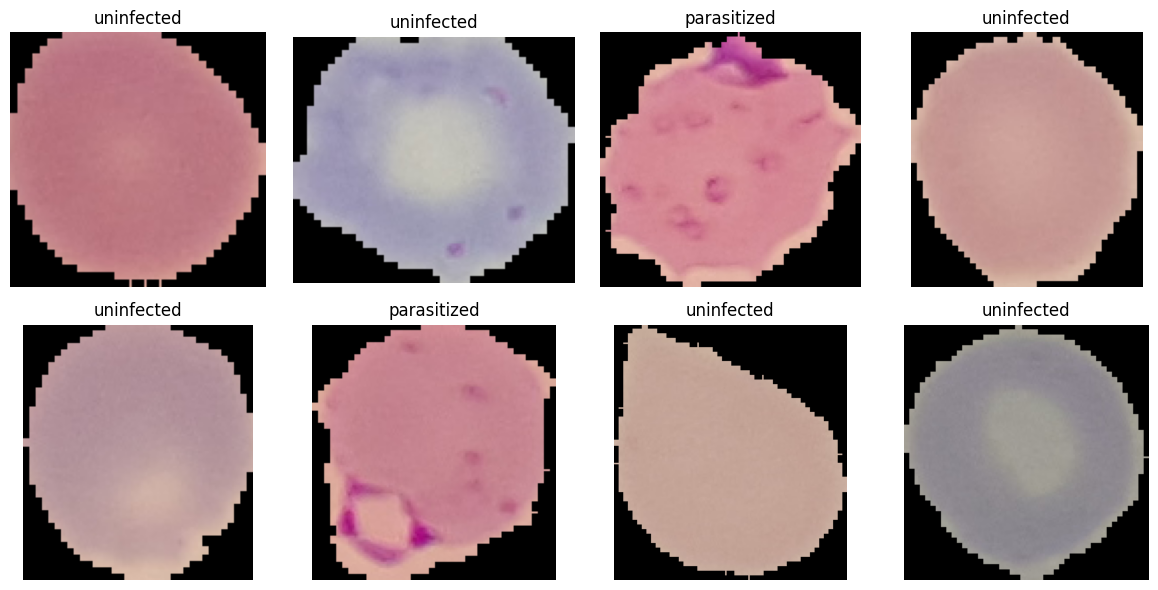

In [27]:


plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(dataset.take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[int(label.numpy())])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Cell 05: Train / Validation / Test Split

In [28]:


import tensorflow_datasets as tfds

# Fixed dataset split
splits = [
    "train[:70%]",
    "train[70%:85%]",
    "train[85%:]"
]

train_ds, val_ds, test_ds = tfds.load(
    "malaria",
    split=splits,
    as_supervised=True,
    shuffle_files=False,
    data_dir="/content/quantum_malaria_data"
)

print("Training:", info.splits[splits[0]].num_examples)
print("Validation:", info.splits[splits[1]].num_examples)
print("Testing:", info.splits[splits[2]].num_examples)

print("Dataset Split Ready!")


Training: 19291
Validation: 4133
Testing: 4134
Dataset Split Ready!


# Cell 06: Data Preprocessing

In [29]:


import tensorflow as tf

# Configuration
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(42)

# Preprocessing Function
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Training Data
train_data = (
    train_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(2000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation Data
val_data = (
    val_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Testing Data
test_data = (
    test_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Verify Data
images, labels = next(iter(train_data))

print("Image Shape:", images.shape)
print("Pixel Min:", tf.reduce_min(images).numpy())
print("Pixel Max:", tf.reduce_max(images).numpy())
print("Preprocessing Successful!")


Image Shape: (32, 128, 128, 3)
Pixel Min: 0.0
Pixel Max: 0.9085246
Preprocessing Successful!



# Cell 07: Advanced CNN Feature Extractor

In [30]:


import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, Model

# Load pretrained EfficientNetB0
base_model = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Input
inputs = layers.Input(shape=(128, 128, 3))

# Data Augmentation
z = layers.RandomFlip(
    "horizontal_and_vertical"
)(inputs)

z = layers.RandomRotation(0.1)(z)

# EfficientNet expects pixel values 0-255
z = layers.Rescaling(255.0)(z)

# Pretrained feature extraction
z = base_model(z, training=False)

z = layers.GlobalAveragePooling2D()(z)

# Feature Representation
z = layers.Dense(
    128,
    activation="relu",
    name="cnn_features"
)(z)

z = layers.Dropout(0.3)(z)

# Binary Classification
outputs = layers.Dense(
    1,
    activation="sigmoid"
)(z)

# Build Model
cnn_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Advanced_Malaria_CNN"
)

# Compile
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Verify
print("Model:", cnn_model.name)
print("Total Parameters:", cnn_model.count_params())
print("Trainable Parameters:", sum(
    np.prod(w.shape)
    for w in cnn_model.trainable_weights
))
print("Output Shape:", cnn_model.output_shape)
print("Feature Dimension: 128")
print("Advanced CNN Created Successfully!")


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Model: Advanced_Malaria_CNN
Total Parameters: 4213668
Trainable Parameters: 164097
Output Shape: (None, 1)
Feature Dimension: 128
Advanced CNN Created Successfully!


# Cell 08: Train Classical CNN

In [31]:


import tensorflow as tf

# Training Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath="/content/malaria_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# Train Model
history = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=callbacks,
    verbose=1
)

# Training Results
best_epoch = int(
    tf.argmax(history.history["val_accuracy"]).numpy()
) + 1

print("\nTraining Completed!")
print("Best Validation Accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")
print("Best Validation Accuracy Epoch:", best_epoch)
print("Best Validation Loss:",
      round(min(history.history["val_loss"]), 4))
print("Model saved to /content/malaria_cnn_best.keras")


Epoch 1/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8757 - loss: 0.2927
Epoch 1: val_loss improved from None to 0.17676, saving model to /content/malaria_cnn_best.keras

Epoch 1: finished saving model to /content/malaria_cnn_best.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 53s 54ms/step - accuracy: 0.9037 - loss: 0.2425 - val_accuracy: 0.9315 - val_loss: 0.1768 - learning_rate: 0.0010
Epoch 2/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9169 - loss: 0.2088
Epoch 2: val_loss improved from 0.17676 to 0.17133, saving model to /content/malaria_cnn_best.keras

Epoch 2: finished saving model to /content/malaria_cnn_best.keras
603/603 ━━━━━━━━━━━━━━━━━━━━ 29s 45ms/step - accuracy: 0.9202 - loss: 0.2041 - val_accuracy: 0.9342 - val_loss: 0.1713 - learning_rate: 0.0010
Epoch 3/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9228 - loss: 0.2006
Epoch 3: val_loss improved from 0.17133 to 0.15645, saving model to /content/malaria_cnn_best.keras

Epoch 3: finished sav


# Cell 09: EfficientNet Fine-Tuning

In [32]:


import tensorflow as tf

# Save baseline validation results
baseline_loss, baseline_accuracy = cnn_model.evaluate(
    val_data, verbose=0
)

print(f"Before Fine-Tuning: {baseline_accuracy * 100:.2f}%")

# Unfreeze EfficientNet
base_model.trainable = True

# Train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a lower learning rate
cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Fine-Tuning Callbacks
callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# Fine-Tuning
history_ft = cnn_model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=callbacks_ft,
    verbose=1
)

# Evaluate after fine-tuning
ft_loss, ft_accuracy = cnn_model.evaluate(
    val_data, verbose=0
)

# Keep the model with the lower validation loss
if ft_loss < baseline_loss:
    cnn_model.save("/content/malaria_cnn_best.keras")
    selected_accuracy = ft_accuracy
    selected_loss = ft_loss
    print("Fine-Tuned Model Saved!")
else:
    cnn_model.load_weights("/content/malaria_cnn_best.keras")
    selected_accuracy = baseline_accuracy
    selected_loss = baseline_loss
    print("Original Best Model Restored!")

print("\nFine-Tuning Results")
print(f"Before Accuracy: {baseline_accuracy * 100:.2f}%")
print(f"After Accuracy: {ft_accuracy * 100:.2f}%")
print(f"Selected Accuracy: {selected_accuracy * 100:.2f}%")
print(f"Selected Loss: {selected_loss:.4f}")


Before Fine-Tuning: 94.87%
Epoch 1/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.9449 - loss: 0.1476 - val_accuracy: 0.9473 - val_loss: 0.1352 - learning_rate: 1.0000e-05
Epoch 2/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 39s 51ms/step - accuracy: 0.9473 - loss: 0.1413 - val_accuracy: 0.9499 - val_loss: 0.1309 - learning_rate: 1.0000e-05
Epoch 3/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 30s 48ms/step - accuracy: 0.9491 - loss: 0.1349 - val_accuracy: 0.9543 - val_loss: 0.1239 - learning_rate: 1.0000e-05
Epoch 4/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 31s 50ms/step - accuracy: 0.9500 - loss: 0.1383 - val_accuracy: 0.9516 - val_loss: 0.1237 - learning_rate: 1.0000e-05
Epoch 5/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 30s 47ms/step - accuracy: 0.9527 - loss: 0.1292 - val_accuracy: 0.9482 - val_loss: 0.1324 - learning_rate: 1.0000e-05
Epoch 6/20
603/603 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9536 - loss: 0.1304
Epoch 6: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
603/603 ━━━━━━━━━━━━


# Cell 10: CNN Feature Extraction for Quantum Learning

In [33]:


import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

# Extract the 128-dimensional CNN representation
feature_extractor = tf.keras.Model(
    inputs=cnn_model.input,
    outputs=cnn_model.get_layer("cnn_features").output
)

def extract_features(dataset):
    all_features = []
    all_labels = []

    for images, labels in dataset:
        features = feature_extractor(
            images, training=False
        )

        all_features.append(features.numpy())
        all_labels.append(labels.numpy())

    return (
        np.concatenate(all_features).astype(np.float32),
        np.concatenate(all_labels).astype(np.int64)
    )

print("Extracting Training Features...")
train_features, train_labels = extract_features(train_data)

print("Extracting Validation Features...")
val_features, val_labels = extract_features(val_data)

# Fit scaling only on training data
feature_scaler = StandardScaler()

X_train = feature_scaler.fit_transform(
    train_features
).astype(np.float32)

X_val = feature_scaler.transform(
    val_features
).astype(np.float32)

# Save features
np.savez_compressed(
    "/content/malaria_quantum_features.npz",
    X_train=X_train,
    y_train=train_labels,
    X_val=X_val,
    y_val=val_labels
)

print("\nFeature Extraction Completed!")
print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)
print("Training Labels:", train_labels.shape)
print("Validation Labels:", val_labels.shape)
print("Feature Dimension:", X_train.shape[1])
print("Saved Successfully!")


Extracting Training Features...
Extracting Validation Features...

Feature Extraction Completed!
Training Features: (19291, 128)
Validation Features: (4133, 128)
Training Labels: (19291,)
Validation Labels: (4133,)
Feature Dimension: 128
Saved Successfully!


# Cell 11: Advanced Hybrid Quantum Model

In [34]:



%pip -q install pennylane

import numpy as np
import pennylane as qml
import torch
import torch.nn as nn

torch.manual_seed(42)

# Quantum Configuration
N_QUBITS = 8
N_Q_LAYERS = 3

# Quantum Simulator
dev = qml.device(
    "default.qubit",
    wires=N_QUBITS,
    shots=None
)

# Trainable Quantum Circuit
@qml.qnode(
    dev,
    interface="torch",
    diff_method="backprop"
)
def quantum_circuit(inputs, weights):

    for layer in range(N_Q_LAYERS):

        # Data Re-uploading
        qml.AngleEmbedding(
            inputs,
            wires=range(N_QUBITS),
            rotation="Y"
        )

        # Quantum Entanglement
        qml.StronglyEntanglingLayers(
            weights[layer:layer + 1],
            wires=range(N_QUBITS)
        )

    return [
        qml.expval(qml.PauliZ(i))
        for i in range(N_QUBITS)
    ]


# Quantum Weight Dimensions
weight_shapes = {
    "weights": (N_Q_LAYERS, N_QUBITS, 3)
}


# Hybrid Quantum-Classical Model
class HybridQuantumModel(nn.Module):

    def __init__(self):
        super().__init__()

        # Learnable Feature Compression
        self.feature_projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, N_QUBITS),
            nn.Tanh()
        )

        # Quantum Layer
        self.quantum_layer = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes
        )

        # Classical Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 16),
            nn.GELU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):

        # Map Features to Quantum Angles
        x = self.feature_projection(x)
        x = torch.pi * x

        # Quantum Processing
        x = self.quantum_layer(x)

        # Final Classification Logits
        x = self.classifier(x.float())

        return x.squeeze(-1)


# Initialize Model
quantum_model = HybridQuantumModel()

# Count Parameters
total_params = sum(
    p.numel()
    for p in quantum_model.parameters()
)

quantum_params = sum(
    p.numel()
    for p in quantum_model.quantum_layer.parameters()
)

print("Qubits:", N_QUBITS)
print("Quantum Layers:", N_Q_LAYERS)
print("Total Trainable Parameters:", total_params)
print("Quantum Parameters:", quantum_params)

# Forward and Backward Test
sample_x = torch.tensor(
    X_train[:2],
    dtype=torch.float32
)

sample_y = torch.tensor(
    train_labels[:2],
    dtype=torch.float32
)

predictions = quantum_model(sample_x)

loss = nn.BCEWithLogitsLoss()(
    predictions,
    sample_y
)

loss.backward()

print("Output Shape:", predictions.shape)
print("Backward Pass Successful!")
print("Advanced Hybrid Quantum Model Ready!")


Qubits: 8
Quantum Layers: 3
Total Trainable Parameters: 9137
Quantum Parameters: 72
Output Shape: torch.Size([2])
Backward Pass Successful!
Advanced Hybrid Quantum Model Ready!



# Cell 12: Train Advanced Hybrid Quantum Model

In [35]:


import torch
import numpy as np
import random
import copy
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Quantum simulation runs on CPU
device = torch.device("cpu")
quantum_model = quantum_model.to(device)

# Prepare Datasets
train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(train_labels, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(val_labels, dtype=torch.float32)
)

BATCH_SIZE_Q = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE_Q,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE_Q,
    shuffle=False
)

# Loss and Optimizer
criterion = torch.nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    quantum_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

# Training Configuration
EPOCHS = 15
PATIENCE = 4

best_val_loss = float("inf")
best_state = None
patience_counter = 0

training_history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

print("Starting Quantum Training...")
print("Training Samples:", len(train_dataset))
print("Validation Samples:", len(val_dataset))
print("Qubits:", N_QUBITS)
print("Quantum Layers:", N_Q_LAYERS)

for epoch in range(EPOCHS):

    # Training
    quantum_model.train()
    running_loss = 0.0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = quantum_model(batch_x)

        loss = criterion(outputs, batch_y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            quantum_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += (
            loss.item() * batch_x.size(0)
        )

    train_loss = running_loss / len(train_dataset)

    # Validation
    quantum_model.eval()

    val_running_loss = 0.0
    all_predictions = []
    all_targets = []

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            outputs = quantum_model(batch_x)

            loss = criterion(outputs, batch_y)

            val_running_loss += (
                loss.item() * batch_x.size(0)
            )

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= 0.5
            ).int()

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_targets.extend(
                batch_y.cpu().numpy()
            )

    val_loss = val_running_loss / len(val_dataset)

    all_predictions = np.array(all_predictions)
    all_targets = np.array(all_targets).astype(int)

    val_accuracy = accuracy_score(
        all_targets, all_predictions
    )

    # Infected class = 0
    val_precision = precision_score(
        all_targets,
        all_predictions,
        pos_label=0,
        zero_division=0
    )

    val_recall = recall_score(
        all_targets,
        all_predictions,
        pos_label=0,
        zero_division=0
    )

    val_f1 = f1_score(
        all_targets,
        all_predictions,
        pos_label=0,
        zero_division=0
    )

    training_history["train_loss"].append(train_loss)
    training_history["val_loss"].append(val_loss)
    training_history["val_accuracy"].append(val_accuracy)
    training_history["val_precision"].append(val_precision)
    training_history["val_recall"].append(val_recall)
    training_history["val_f1"].append(val_f1)

    scheduler.step(val_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy*100:.2f}% | "
        f"Recall: {val_recall*100:.2f}% | "
        f"F1: {val_f1*100:.2f}%",
        flush=True
    )

    # Save Best Model
    if val_loss < best_val_loss - 1e-5:

        best_val_loss = val_loss

        best_state = copy.deepcopy(
            quantum_model.state_dict()
        )

        torch.save(
            {
                "model_state_dict": best_state,
                "epoch": epoch + 1,
                "val_loss": val_loss,
                "val_accuracy": val_accuracy,
                "val_precision": val_precision,
                "val_recall": val_recall,
                "val_f1": val_f1,
                "n_qubits": N_QUBITS,
                "n_layers": N_Q_LAYERS
            },
            "/content/best_hybrid_quantum.pth"
        )

        patience_counter = 0

        print("Best Quantum Model Saved!")

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early Stopping Activated!")
            break

# Restore Best Weights
if best_state is not None:
    quantum_model.load_state_dict(best_state)

print("\nQuantum Training Completed!")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print("Saved: /content/best_hybrid_quantum.pth")


Starting Quantum Training...
Training Samples: 19291
Validation Samples: 4133
Qubits: 8
Quantum Layers: 3
Epoch 1/15 | Train Loss: 0.2360 | Val Loss: 0.1237 | Accuracy: 95.86% | Recall: 94.49% | F1: 95.78%
Best Quantum Model Saved!
Epoch 2/15 | Train Loss: 0.1140 | Val Loss: 0.1254 | Accuracy: 95.55% | Recall: 93.62% | F1: 95.43%
Epoch 3/15 | Train Loss: 0.1090 | Val Loss: 0.1173 | Accuracy: 95.98% | Recall: 95.32% | F1: 95.93%
Best Quantum Model Saved!
Epoch 4/15 | Train Loss: 0.1058 | Val Loss: 0.1196 | Accuracy: 95.67% | Recall: 95.81% | F1: 95.65%
Epoch 5/15 | Train Loss: 0.1042 | Val Loss: 0.1201 | Accuracy: 95.74% | Recall: 95.03% | F1: 95.68%
Epoch 6/15 | Train Loss: 0.1020 | Val Loss: 0.1187 | Accuracy: 95.81% | Recall: 95.57% | F1: 95.78%
Epoch 7/15 | Train Loss: 0.0960 | Val Loss: 0.1178 | Accuracy: 95.86% | Recall: 94.40% | F1: 95.77%
Early Stopping Activated!

Quantum Training Completed!
Best Validation Loss: 0.1173
Saved: /content/best_hybrid_quantum.pth



# Cell 13: Fair Validation Comparison

In [36]:


import numpy as np
import torch
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# True labels from validation dataset
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_data
]).astype(int)

assert np.array_equal(y_true, val_labels), \
    "Validation label order mismatch!"

# Classical CNN predictions
cnn_probs = cnn_model.predict(
    val_data,
    verbose=0
).reshape(-1)

# Quantum predictions
quantum_model.eval()

quantum_probs = []

with torch.no_grad():
    for start in range(0, len(X_val), 32):
        batch = torch.tensor(
            X_val[start:start + 32],
            dtype=torch.float32
        )

        logits = quantum_model(batch)
        probs = torch.sigmoid(logits)

        quantum_probs.extend(
            probs.cpu().numpy()
        )

quantum_probs = np.array(quantum_probs)

# Calculate metrics for infected class (label 0)
def evaluate_model(name, probabilities):
    predictions = (probabilities >= 0.5).astype(int)

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions) * 100,
        "Precision": precision_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "F1": f1_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "ROC-AUC": roc_auc_score(
            (y_true == 0).astype(int),
            1.0 - probabilities
        ) * 100,
        "Missed Infected": int(cm[0, 1])
    }

results = pd.DataFrame([
    evaluate_model("Classical CNN", cnn_probs),
    evaluate_model("Hybrid Quantum", quantum_probs)
])

print("\nVALIDATION COMPARISON")
print(results.round(2).to_string(index=False))

print("\nAccuracy Difference (Quantum - CNN):")
print(
    f"{results.iloc[1]['Accuracy'] - results.iloc[0]['Accuracy']:+.2f} percentage points"
)

print("\nTest Dataset Remains Untouched.")



VALIDATION COMPARISON
         Model  Accuracy  Precision  Recall    F1  ROC-AUC  Missed Infected
 Classical CNN     95.60      96.61   94.44 95.52    99.16              114
Hybrid Quantum     95.98      96.54   95.32 95.93    99.14               96

Accuracy Difference (Quantum - CNN):
+0.39 percentage points

Test Dataset Remains Untouched.



# Cell 14: Matched Classical MLP Baseline

In [37]:


import torch
import torch.nn as nn
import numpy as np
import copy
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

torch.manual_seed(42)

class ClassicalMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.feature_projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Linear(64, 8),
            nn.Tanh()
        )

        self.classifier = nn.Sequential(
            nn.Linear(8, 16),
            nn.GELU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        x = self.feature_projection(x)
        return self.classifier(x).squeeze(-1)


mlp_model = ClassicalMLP().to("cpu")

mlp_params = sum(
    p.numel() for p in mlp_model.parameters()
)

quantum_params_total = sum(
    p.numel() for p in quantum_model.parameters()
)

print("Classical MLP Parameters:", mlp_params)
print("Hybrid Quantum Parameters:", quantum_params_total)

criterion_mlp = nn.BCEWithLogitsLoss()

optimizer_mlp = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler_mlp = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_mlp,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

best_mlp_loss = float("inf")
best_mlp_state = None
patience_count = 0

for epoch in range(15):

    mlp_model.train()
    train_loss_total = 0.0

    for x, y in train_loader:
        optimizer_mlp.zero_grad(set_to_none=True)

        logits = mlp_model(x)
        loss = criterion_mlp(logits, y)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            mlp_model.parameters(), 1.0
        )

        optimizer_mlp.step()

        train_loss_total += loss.item() * len(x)

    mlp_model.eval()
    val_loss_total = 0.0

    with torch.no_grad():
        for x, y in val_loader:
            logits = mlp_model(x)
            loss = criterion_mlp(logits, y)
            val_loss_total += loss.item() * len(x)

    current_loss = val_loss_total / len(val_dataset)
    scheduler_mlp.step(current_loss)

    print(
        f"Epoch {epoch+1}/15 | "
        f"Train Loss: {train_loss_total/len(train_dataset):.4f} | "
        f"Val Loss: {current_loss:.4f}",
        flush=True
    )

    if current_loss < best_mlp_loss - 1e-5:
        best_mlp_loss = current_loss
        best_mlp_state = copy.deepcopy(
            mlp_model.state_dict()
        )
        patience_count = 0
    else:
        patience_count += 1

        if patience_count >= 4:
            print("Early Stopping!")
            break

mlp_model.load_state_dict(best_mlp_state)
mlp_model.eval()

torch.save(
    best_mlp_state,
    "/content/best_classical_mlp.pth"
)

mlp_probs = []

with torch.no_grad():
    for x, _ in val_loader:
        probabilities = torch.sigmoid(mlp_model(x))
        mlp_probs.extend(probabilities.cpu().numpy())

mlp_probs = np.array(mlp_probs)
mlp_preds = (mlp_probs >= 0.5).astype(int)

cm = confusion_matrix(
    val_labels,
    mlp_preds,
    labels=[0, 1]
)

mlp_metrics = {
    "Accuracy": accuracy_score(val_labels, mlp_preds) * 100,
    "Precision": precision_score(
        val_labels, mlp_preds,
        pos_label=0, zero_division=0
    ) * 100,
    "Recall": recall_score(
        val_labels, mlp_preds,
        pos_label=0, zero_division=0
    ) * 100,
    "F1": f1_score(
        val_labels, mlp_preds,
        pos_label=0, zero_division=0
    ) * 100,
    "ROC-AUC": roc_auc_score(
        (val_labels == 0).astype(int),
        1 - mlp_probs
    ) * 100
}

print("\nCLASSICAL MLP RESULTS")

for metric, value in mlp_metrics.items():
    print(f"{metric}: {value:.2f}%")

print("Missed Infected:", cm[0, 1])
print("Best Validation Loss:", round(best_mlp_loss, 4))
print("MLP Model Saved!")


Classical MLP Parameters: 9065
Hybrid Quantum Parameters: 9137
Epoch 1/15 | Train Loss: 0.1642 | Val Loss: 0.1182
Epoch 2/15 | Train Loss: 0.1086 | Val Loss: 0.1142
Epoch 3/15 | Train Loss: 0.1059 | Val Loss: 0.1155
Epoch 4/15 | Train Loss: 0.1026 | Val Loss: 0.1181
Epoch 5/15 | Train Loss: 0.1007 | Val Loss: 0.1161
Epoch 6/15 | Train Loss: 0.0968 | Val Loss: 0.1201
Early Stopping!

CLASSICAL MLP RESULTS
Accuracy: 95.91%
Precision: 97.24%
Recall: 94.44%
F1: 95.82%
ROC-AUC: 99.15%
Missed Infected: 114
Best Validation Loss: 0.1142
MLP Model Saved!


# Cell 15: Quantum vs Classical Statistical Test

In [38]:



import numpy as np
from scipy.stats import binomtest

# True validation labels
y_true = np.asarray(val_labels).astype(int)

# Model predictions
q_pred = (np.asarray(quantum_probs) >= 0.5).astype(int)
mlp_pred = (np.asarray(mlp_probs) >= 0.5).astype(int)

assert len(y_true) == len(q_pred) == len(mlp_pred)

# Correct predictions
q_correct = q_pred == y_true
mlp_correct = mlp_pred == y_true

# Paired comparisons
quantum_only_correct = np.sum(
    q_correct & ~mlp_correct
)

mlp_only_correct = np.sum(
    mlp_correct & ~q_correct
)

# Exact McNemar test
discordant = quantum_only_correct + mlp_only_correct

if discordant > 0:
    p_value = binomtest(
        int(quantum_only_correct),
        n=int(discordant),
        p=0.5
    ).pvalue
else:
    p_value = 1.0

# Paired bootstrap confidence interval
rng = np.random.default_rng(42)
n_samples = len(y_true)
differences = []

for _ in range(3000):
    idx = rng.integers(
        0, n_samples, size=n_samples
    )

    difference = (
        q_correct[idx].mean()
        - mlp_correct[idx].mean()
    ) * 100

    differences.append(difference)

ci_low, ci_high = np.percentile(
    differences, [2.5, 97.5]
)

print("QUANTUM VS CLASSICAL MLP")
print("-" * 40)

print("Quantum Only Correct:", quantum_only_correct)
print("MLP Only Correct:", mlp_only_correct)

print(f"\nMcNemar p-value: {p_value:.6f}")

print(
    f"Accuracy Difference 95% CI: "
    f"[{ci_low:+.3f}, {ci_high:+.3f}] "
    "percentage points"
)

if p_value < 0.05:
    print(
        "\nStatistically significant "
        "accuracy difference."
    )
else:
    print(
        "\nNo statistically significant "
        "accuracy difference detected."
    )

print("\nStatistical Analysis Completed!")


QUANTUM VS CLASSICAL MLP
----------------------------------------
Quantum Only Correct: 25
MLP Only Correct: 22

McNemar p-value: 0.770867
Accuracy Difference 95% CI: [-0.242, +0.387] percentage points

No statistically significant accuracy difference detected.

Statistical Analysis Completed!


# Cell 16: Threshold Optimization


In [39]:


import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    confusion_matrix
)

y_true = np.asarray(val_labels).astype(int)
y_infected = (y_true == 0).astype(int)

models = {
    "Classical CNN": np.asarray(cnn_probs),
    "Classical MLP": np.asarray(mlp_probs),
    "Hybrid Quantum": np.asarray(quantum_probs)
}

selected_thresholds = {}
comparison = []

thresholds = np.linspace(0.05, 0.95, 181)

for name, probs_healthy in models.items():

    probs_infected = 1.0 - probs_healthy

    best_threshold = 0.5
    best_f2 = -1.0

    for threshold in thresholds:

        predicted_infected = (
            probs_infected >= threshold
        ).astype(int)

        score = fbeta_score(
            y_infected,
            predicted_infected,
            beta=2,
            zero_division=0
        )

        if score > best_f2:
            best_f2 = score
            best_threshold = float(threshold)

    selected_thresholds[name] = best_threshold

    predicted_infected = (
        probs_infected >= best_threshold
    ).astype(int)

    predictions = 1 - predicted_infected

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    comparison.append({
        "Model": name,
        "Threshold": best_threshold,
        "Accuracy": accuracy_score(
            y_true, predictions
        ) * 100,
        "Precision": precision_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "F1": f1_score(
            y_true, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "F2": best_f2 * 100,
        "Missed Infected": int(cm[0, 1]),
        "False Alarms": int(cm[1, 0])
    })

threshold_results = pd.DataFrame(comparison)

print("\nOPTIMIZED VALIDATION RESULTS")
print("-" * 65)
print(
    threshold_results.round(2).to_string(index=False)
)

print("\nSelected Thresholds:")
for name, threshold in selected_thresholds.items():
    print(f"{name}: {threshold:.3f}")

print("\nValidation Threshold Optimization Completed!")
print("Test Dataset Remains Untouched.")



OPTIMIZED VALIDATION RESULTS
-----------------------------------------------------------------
         Model  Threshold  Accuracy  Precision  Recall    F1    F2  Missed Infected  False Alarms
 Classical CNN       0.15     93.44      89.53   98.29 93.70 96.41               35           236
 Classical MLP       0.20     94.80      92.31   97.66 94.91 96.54               48           167
Hybrid Quantum       0.30     95.35      93.87   96.98 95.40 96.34               62           130

Selected Thresholds:
Classical CNN: 0.155
Classical MLP: 0.200
Hybrid Quantum: 0.305

Validation Threshold Optimization Completed!
Test Dataset Remains Untouched.



# Cell 17: Quantum Fine-Tuning for Better F2

In [40]:


import torch
import numpy as np
import copy

from sklearn.metrics import fbeta_score, recall_score

# Preserve original quantum model
original_state = copy.deepcopy(
    quantum_model.state_dict()
)

# Previously selected validation threshold
q_threshold = selected_thresholds["Hybrid Quantum"]

# Validation function
def evaluate_quantum_f2(model):
    model.eval()
    probabilities = []

    with torch.no_grad():
        for x, _ in val_loader:
            logits = model(x)
            probabilities.extend(
                torch.sigmoid(logits).cpu().numpy()
            )

    probabilities = np.asarray(probabilities)

    infected_predictions = (
        1.0 - probabilities >= q_threshold
    ).astype(int)

    infected_targets = (val_labels == 0).astype(int)

    f2 = fbeta_score(
        infected_targets,
        infected_predictions,
        beta=2,
        zero_division=0
    )

    recall = recall_score(
        infected_targets,
        infected_predictions,
        zero_division=0
    )

    missed = int(
        np.sum(
            (infected_targets == 1) &
            (infected_predictions == 0)
        )
    )

    return f2, recall, missed


# Baseline
baseline_f2, baseline_recall, baseline_missed = (
    evaluate_quantum_f2(quantum_model)
)

print(f"Original F2: {baseline_f2 * 100:.2f}%")
print(f"Original Recall: {baseline_recall * 100:.2f}%")
print(f"Original Missed Infected: {baseline_missed}")

# Fine-tuning optimizer
optimizer_ft = torch.optim.AdamW(
    quantum_model.parameters(),
    lr=0.0002,
    weight_decay=0.0001
)

criterion_ft = torch.nn.BCEWithLogitsLoss(
    reduction="none"
)

best_f2 = baseline_f2
best_state = copy.deepcopy(original_state)
best_epoch = 0
patience = 0

for epoch in range(1, 7):

    quantum_model.train()
    running_loss = 0.0

    for x, y in train_loader:

        optimizer_ft.zero_grad(set_to_none=True)

        logits = quantum_model(x)


        sample_weights = torch.where(
            y == 0,
            torch.tensor(1.2),
            torch.tensor(1.0)
        )

        loss = (
            criterion_ft(logits, y) *
            sample_weights
        ).mean()

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            quantum_model.parameters(),
            max_norm=1.0
        )

        optimizer_ft.step()

        running_loss += loss.item() * len(x)

    val_f2, val_recall, missed = (
        evaluate_quantum_f2(quantum_model)
    )

    print(
        f"Epoch {epoch}/6 | "
        f"Loss: {running_loss / len(train_dataset):.4f} | "
        f"F2: {val_f2 * 100:.2f}% | "
        f"Recall: {val_recall * 100:.2f}% | "
        f"Missed: {missed}",
        flush=True
    )

    if val_f2 > best_f2 + 1e-5:
        best_f2 = val_f2
        best_state = copy.deepcopy(
            quantum_model.state_dict()
        )
        best_epoch = epoch
        patience = 0
    else:
        patience += 1

        if patience >= 3:
            print("Early Stopping!")
            break

if best_epoch > 0:
    torch.save(
        {
            "model_state_dict": best_state,
            "threshold": q_threshold,
            "validation_f2": best_f2,
            "epoch": best_epoch
        },
        "/content/best_hybrid_quantum_f2.pth"
    )

    print("\nImproved Quantum Candidate Saved!")
else:
    print("\nNo improvement over original model.")

quantum_model.load_state_dict(original_state)

print("\nFINAL COMPARISON")
print(f"Original F2: {baseline_f2 * 100:.2f}%")
print(f"Best Fine-Tuned F2: {best_f2 * 100:.2f}%")
print("Original Quantum Model Preserved.")
print("Test Dataset Untouched.")


Original F2: 96.34%
Original Recall: 96.98%
Original Missed Infected: 62
Epoch 1/6 | Loss: 0.1110 | F2: 96.33% | Recall: 97.03% | Missed: 61
Epoch 2/6 | Loss: 0.1085 | F2: 96.10% | Recall: 96.69% | Missed: 68
Epoch 3/6 | Loss: 0.1068 | F2: 95.87% | Recall: 96.20% | Missed: 78
Early Stopping!

No improvement over original model.

FINAL COMPARISON
Original F2: 96.34%
Best Fine-Tuned F2: 96.34%
Original Quantum Model Preserved.
Test Dataset Untouched.



# Cell 18: Save Final Research Checkpoint

In [42]:


import os
import json
import joblib
import torch
import zipfile

folder = "/content/quantum_malaria_final"
os.makedirs(folder, exist_ok=True)

cnn_model.save(f"{folder}/cnn.keras")

torch.save(
    quantum_model.state_dict(),
    f"{folder}/quantum.pth"
)

torch.save(
    mlp_model.state_dict(),
    f"{folder}/mlp.pth"
)

joblib.dump(
    feature_scaler,
    f"{folder}/scaler.joblib"
)

config = {
    "qubits": 8,
    "quantum_layers": 3,
    "feature_dimensions": 128,
    "infected_label": 0,
    "thresholds": {
        name: float(value)
        for name, value in selected_thresholds.items()
    }
}

with open(f"{folder}/config.json", "w") as f:
    json.dump(config, f, indent=4)


zip_path = "/content/quantum_malaria_final.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for filename in os.listdir(folder):
        archive.write(
            f"{folder}/{filename}",
            arcname=filename
        )

print("All Models Saved Successfully!")
print("Backup:", zip_path)


All Models Saved Successfully!
Backup: /content/quantum_malaria_final.zip



# Cell 19: Final Test Evaluation

In [43]:

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix
)


print("Extracting Test Features...")

test_features, test_labels = extract_features(test_data)

X_test = feature_scaler.transform(
    test_features
).astype(np.float32)

y_test = test_labels.astype(int)

print("Evaluating CNN...")

cnn_test_probs = cnn_model.predict(
    test_data, verbose=0
).reshape(-1)


print("Evaluating Quantum...")

quantum_model.eval()
quantum_test_probs = []

with torch.no_grad():
    for start in range(0, len(X_test), 32):
        batch = torch.tensor(
            X_test[start:start + 32],
            dtype=torch.float32
        )
        logits = quantum_model(batch)
        quantum_test_probs.extend(
            torch.sigmoid(logits).cpu().numpy()
        )

quantum_test_probs = np.asarray(quantum_test_probs)

print("Evaluating MLP...")

mlp_model.eval()
mlp_test_probs = []

with torch.no_grad():
    for start in range(0, len(X_test), 32):
        batch = torch.tensor(
            X_test[start:start + 32],
            dtype=torch.float32
        )
        logits = mlp_model(batch)
        mlp_test_probs.extend(
            torch.sigmoid(logits).cpu().numpy()
        )

mlp_test_probs = np.asarray(mlp_test_probs)

# 5. Final Metrics
def test_metrics(name, probs, threshold, setting):

    infected_probs = 1.0 - probs

    predictions = np.where(
        infected_probs >= threshold, 0, 1
    )

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    return {
        "Model": name,
        "Setting": setting,
        "Accuracy": accuracy_score(
            y_test, predictions
        ) * 100,
        "Precision": precision_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "F1": f1_score(
            y_test, predictions,
            pos_label=0, zero_division=0
        ) * 100,
        "F2": fbeta_score(
            y_test, predictions,
            beta=2, pos_label=0,
            zero_division=0
        ) * 100,
        "ROC-AUC": roc_auc_score(
            (y_test == 0).astype(int),
            infected_probs
        ) * 100,
        "Missed Infected": int(cm[0, 1]),
        "False Alarms": int(cm[1, 0])
    }

models = {
    "Classical CNN": cnn_test_probs,
    "Classical MLP": mlp_test_probs,
    "Hybrid Quantum": quantum_test_probs
}

results = []

for name, probs in models.items():

    results.append(
        test_metrics(name, probs, 0.5, "Default")
    )

    results.append(
        test_metrics(
            name,
            probs,
            selected_thresholds[name],
            "Val Optimized"
        )
    )

final_results = pd.DataFrame(results)

print("\nFINAL TEST RESULTS")
print("=" * 90)
print("Test Samples:", len(y_test))
print(final_results.round(2).to_string(index=False))

print("\nFinal Evaluation Completed!")


Extracting Test Features...
Evaluating CNN...
Evaluating Quantum...
Evaluating MLP...

FINAL TEST RESULTS
Test Samples: 4134
         Model       Setting  Accuracy  Precision  Recall    F1    F2  ROC-AUC  Missed Infected  False Alarms
 Classical CNN       Default     95.28      97.11   93.43 95.24 94.15    98.92              137            58
 Classical CNN Val Optimized     92.86      89.26   97.60 93.24 95.81    98.92               50           245
 Classical MLP       Default     95.09      97.15   93.00 95.03 93.80    98.93              146            57
 Classical MLP Val Optimized     94.29      92.28   96.79 94.48 95.85    98.93               67           169
Hybrid Quantum       Default     95.26      96.64   93.86 95.23 94.41    98.88              128            68
Hybrid Quantum Val Optimized     94.94      94.16   95.93 95.04 95.57    98.88               85           124

Final Evaluation Completed!
